<a href="https://colab.research.google.com/github/MontesCarol/BioData/blob/main/analisis_biologico.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Abs = 0.677*conc + 0.012 | R² = 0.999
Hermetia illucens 0.5 mg/mL
Tenebrio molitor 0.6 mg/mL
Acheta domesticus 0.54 mg/mL


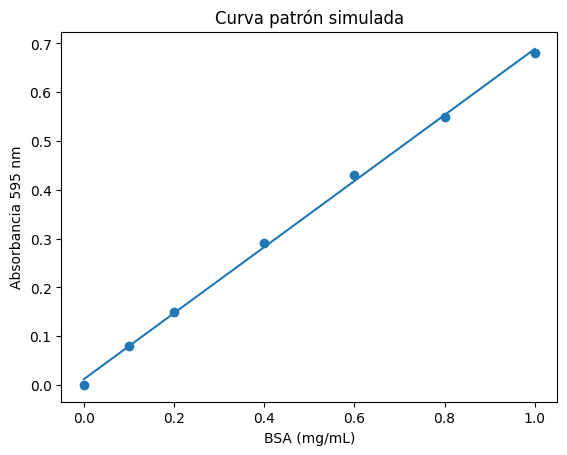

In [1]:
import numpy as np
import matplotlib.pyplot as plt

bsa = np.array([0, 0.1, 0.2, 0.4, 0.6, 0.8, 1.0])  # mg/mL
abs595 = np.array([0, 0.08, 0.15, 0.29, 0.43, 0.55, 0.68])  # simulado

m, b = np.polyfit(bsa, abs595, 1)
r2 = np.corrcoef(bsa, abs595)[0, 1] ** 2
print(f"Abs = {m:.3f}*conc + {b:.3f} | R² = {r2:.3f}")

muestras = {"Hermetia illucens": 0.35,
            "Tenebrio molitor": 0.42,
            "Acheta domesticus": 0.38}  # simulado
for nombre, a in muestras.items():
    print(nombre, round((a - b) / m, 2), "mg/mL")

plt.scatter(bsa, abs595)
plt.plot(bsa, m * bsa + b)
plt.xlabel("BSA (mg/mL)")
plt.ylabel("Absorbancia 595 nm")
plt.title("Curva patrón simulada")
plt.show()

In [2]:
import random
from collections import Counter

padre = ["A", "a"]
madre = ["A", "a"]

teorico = Counter("".join(sorted(p + m)) for p in padre for m in madre)
print("Teórico:", teorico)

sim = Counter("".join(sorted(random.choice(padre) + random.choice(madre)))
              for _ in range(1000))
print("Simulación (1000 crías):", sim)

Teórico: Counter({'Aa': 2, 'AA': 1, 'aa': 1})
Simulación (1000 crías): Counter({'Aa': 485, 'aa': 269, 'AA': 246})


In [3]:
def contenido_gc(seq):
    return (seq.count("G") + seq.count("C")) / len(seq) * 100

secuencias = {"Ejemplo_1": "ATGCGCGTATAGCGC",
              "Ejemplo_2": "ATATTTAAGCATATA"}  # inventadas
for nombre, s in secuencias.items():
    print(nombre, round(contenido_gc(s), 1), "% GC")

Ejemplo_1 60.0 % GC
Ejemplo_2 13.3 % GC
